In [1]:
import pandas as pd
df=pd.read_excel('/home/elena/esercizi/energyef/ENB2012_data.xlsx')
df.head()

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


In [37]:
df.shape

(768, 9)

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      768 non-null    float64
 1   X2      768 non-null    float64
 2   X3      768 non-null    float64
 3   X4      768 non-null    float64
 4   X5      768 non-null    float64
 5   X6      768 non-null    int64  
 6   X7      768 non-null    float64
 7   X8      768 non-null    int64  
 8   Y1      768 non-null    float64
 9   Y2      768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


In [3]:
df.describe().round()

,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
count,768.0,768.0,768.0,768.0,768.0,768.0,768.0,768.0,768.0,768.0
mean,1.0,672.0,318.0,177.0,5.0,4.0,0.0,3.0,22.0,25.0
std,0.0,88.0,44.0,45.0,2.0,1.0,0.0,2.0,10.0,10.0
min,1.0,514.0,245.0,110.0,4.0,2.0,0.0,0.0,6.0,11.0
25%,1.0,606.0,294.0,141.0,4.0,3.0,0.0,2.0,13.0,16.0
50%,1.0,674.0,318.0,184.0,5.0,4.0,0.0,3.0,19.0,22.0
75%,1.0,741.0,343.0,220.0,7.0,4.0,0.0,4.0,32.0,33.0
max,1.0,808.0,416.0,220.0,7.0,5.0,0.0,5.0,43.0,48.0


<Axes: xlabel='Y1', ylabel='Count'>

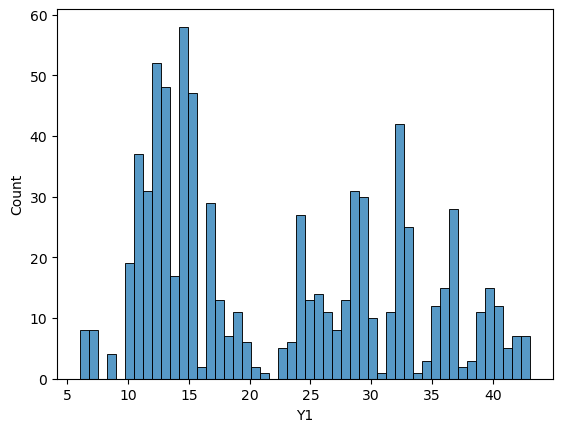

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.histplot(df.Y1, bins=50)

In [5]:
df=df.drop(columns=['Y2'])

In [6]:
df.columns

Index(['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'Y1'], dtype='str')

In [7]:
from sklearn.model_selection import train_test_split
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)


In [8]:
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [9]:
len(df_train), len(df_val), len(df_test)

(460, 154, 154)

In [10]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [11]:
import numpy as np
y_train = df_train.Y1.values
y_val = df_val.Y1.values
y_test = df_test.Y1.values

In [12]:
del df_train['Y1']
del df_val['Y1']
del df_test['Y1']

In [13]:
df_full_train = df_full_train.reset_index(drop=True)

In [14]:
df_full_train.Y1.describe()

count    614.000000
mean      22.057306
std       10.091212
min        6.010000
25%       12.930000
50%       18.250000
75%       31.637500
max       43.100000
Name: Y1, dtype: float64

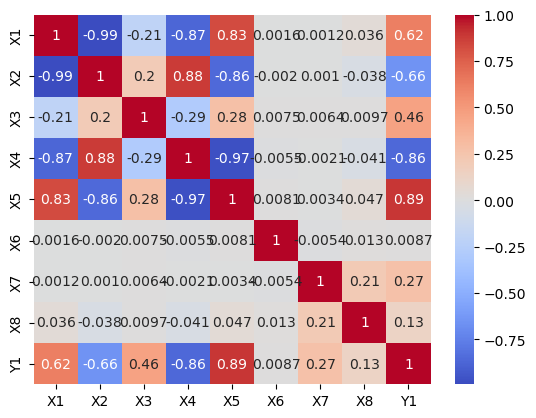

In [15]:
corr_matrix = df_full_train.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.show()

In [16]:
df_full_train.groupby('X7')['Y1'].agg(['mean', 'median', 'count'])

,mean,median,count
X7,,,
0.00,13.540923,10.770,39
0.10,20.484175,15.410,194
0.25,22.178010,17.125,196
0.40,25.374432,19.480,185


In [17]:
df_full_train.groupby('X1')['Y1'].agg(['mean', 'median', 'count'])

,mean,median,count
X1,,,
0.62,14.371731,14.340,52
0.64,16.724545,16.840,55
0.66,12.697843,12.930,51
0.69,12.223200,12.400,50
0.71,11.946291,12.270,55
0.74,11.800566,12.160,53
0.76,35.682745,36.280,51
0.79,38.679388,38.840,49
0.82,25.304000,25.480,45


In [18]:
df_full_train.groupby('X8')['Y1'].agg(['mean', 'median', 'count'])

,mean,median,count
X8,,,
0,13.540923,10.770,39
1,22.535000,19.390,106
2,22.602269,18.880,119
3,21.715424,16.845,118
4,22.786000,19.060,115
5,23.537607,24.350,117


In [19]:
from sklearn.feature_selection import mutual_info_regression
X = df_full_train.drop(columns=['Y1'])
y = df_full_train['Y1']
mi_scores = mutual_info_regression(X, y)
result = pd.Series(mi_scores, index=X.columns).sort_values(ascending=False)
print(result)

X2    1.601123
X1    1.595618
X3    1.021784
X4    0.895256
X7    0.652696
X5    0.647297
X8    0.173576
X6    0.000000
dtype: float64


In [20]:
from sklearn.linear_model import LogisticRegression
features = ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8']
X_train = df_train[features].values
X_val = df_val[features].values

In [21]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [22]:
y_pred = model.predict(X_val)

In [23]:
from sklearn.metrics import mean_squared_error
import numpy as np

rmse = np.sqrt(mean_squared_error(y_val, y_pred))
print(f"RMSE: {rmse}")

RMSE: 2.8593429789437104


In [24]:
import pickle
with open('model.bin', 'wb') as f_out:
    pickle.dump(model, f_out)

In [25]:
from sklearn.tree import DecisionTreeRegressor


In [26]:
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
from sklearn.metrics import mean_squared_error

In [28]:
for depth in [1, 2, 3, 4, 5, 10, 15, 20, None]:
    dt = DecisionTreeRegressor(max_depth=depth, random_state=1)
    dt.fit(X_train, y_train)
    
    y_pred = dt.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    
    # Convertiamo depth in stringa per evitare errori quando è None
    print(f"max_depth={str(depth):>4} -> RMSE: {rmse:.4f}")

max_depth=   1 -> RMSE: 4.7401
max_depth=   2 -> RMSE: 3.4326
max_depth=   3 -> RMSE: 2.4373
max_depth=   4 -> RMSE: 1.6356
max_depth=   5 -> RMSE: 1.1060
max_depth=  10 -> RMSE: 0.5763
max_depth=  15 -> RMSE: 0.5816
max_depth=  20 -> RMSE: 0.5816
max_depth=None -> RMSE: 0.5816


In [29]:
scores = []

for depth in [4, 5, 10]:
    for leaf in [1, 2, 5, 10, 15, 20]:
        dt = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf, random_state=1)
        dt.fit(X_train, y_train)
        
        y_pred = dt.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, y_pred))
        
        scores.append((depth, leaf, rmse))

df_scores = pd.DataFrame(scores, columns=['max_depth', 'min_samples_leaf', 'rmse'])
df_scores.sort_values(by='rmse').head(10)

,max_depth,min_samples_leaf,rmse
13,10,2,0.544891
12,10,1,0.576297
14,10,5,0.724218
6,5,1,1.106026
7,5,2,1.106026
8,5,5,1.200699
15,10,10,1.443067
9,5,10,1.534847
1,4,2,1.635632
0,4,1,1.635632


In [30]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

# Addestriamo il Decision Tree con max_depth=10
dt = DecisionTreeRegressor(max_depth=10, random_state=1)
dt.fit(X_train, y_train)

# Valutazione sul validation set
y_pred = dt.predict(X_val)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))

print(f"Decision Tree (max_depth=10) -> RMSE: {rmse:.4f}")

Decision Tree (max_depth=10) -> RMSE: 0.5763


In [31]:
from sklearn.ensemble import RandomForestRegressor
import pandas as pd

scores = []

# Ciclo per stimare il numero ottimale di estimatori e la profondità
for n in range(10, 201, 10):
    for d in [10, 15, 20, 25]:
        rf = RandomForestRegressor(n_estimators=n, max_depth=d, random_state=1, n_jobs=-1)
        rf.fit(X_train, y_train)
        
        y_pred = rf.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, y_pred))
        
        scores.append((n, d, rmse))

# Creiamo un DataFrame per analizzare i risultati
df_scores = pd.DataFrame(scores, columns=['n_estimators', 'max_depth', 'rmse'])
print(df_scores.sort_values(by='rmse').head(10))

    n_estimators  max_depth      rmse
14            40         20  0.464349
15            40         25  0.464349
13            40         15  0.464349
12            40         10  0.464850
10            30         20  0.465435
9             30         15  0.465435
11            30         25  0.465435
8             30         10  0.465582
25            70         15  0.465584
27            70         25  0.465584


In [32]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import numpy as np

# Addestramento della Random Forest con i parametri ottimali
rf = RandomForestRegressor(
    n_estimators=40, 
    max_depth=20, 
    random_state=1, 
    n_jobs=-1
)
rf.fit(X_train, y_train)

# Predizione e calcolo dell'RMSE sul validation set
y_pred_rf = rf.predict(X_val)
rmse_rf = np.sqrt(mean_squared_error(y_val, y_pred_rf))

print(f"Random Forest (n_estimators=40, max_depth=20) -> RMSE: {rmse_rf:.4f}")

Random Forest (n_estimators=40, max_depth=20) -> RMSE: 0.4643


In [33]:
import xgboost as xgb
from sklearn.metrics import mean_squared_error
import numpy as np

# 1. Creazione delle DMatrix (struttura dati ottimizzata per XGBoost)
features = ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8']
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

# 2. Definizione dei parametri iniziali
xgb_params = {
    'eta': 0.3,              # Learning rate (velocità di apprendimento)
    'max_depth': 6,          # Profondità massima degli alberi
    'min_child_weight': 1,   # Peso minimo dei nodi foglia
    'objective': 'reg:squarederror', # Obiettivo per regressione
    'nthread': 8,            # Numero di thread della CPU da usare
    'seed': 1,               # Riproducibilità
    'verbosity': 1
}

# 3. Addestramento monitorando il validation set (watchlist)
watchlist = [(dtrain, 'train'), (dval, 'val')]

model = xgb.train(
    xgb_params, 
    dtrain, 
    num_boost_round=100, 
    evals=watchlist,
    early_stopping_rounds=10
)

# 4. Predizione e calcolo dell'RMSE
y_pred_xgb = model.predict(dval)
rmse_xgb = np.sqrt(mean_squared_error(y_val, y_pred_xgb))

print(f"\nXGBoost RMSE finale: {rmse_xgb:.4f}")

[0]	train-rmse:7.25802	val-rmse:7.08515
[1]	train-rmse:5.20873	val-rmse:5.09328
[2]	train-rmse:3.73625	val-rmse:3.68646
[3]	train-rmse:2.69797	val-rmse:2.68897
[4]	train-rmse:1.96664	val-rmse:1.98426
[5]	train-rmse:1.45219	val-rmse:1.48039
[6]	train-rmse:1.09199	val-rmse:1.13765
[7]	train-rmse:0.84539	val-rmse:0.89979
[8]	train-rmse:0.67280	val-rmse:0.73625
[9]	train-rmse:0.55326	val-rmse:0.62146
[10]	train-rmse:0.47482	val-rmse:0.55741
[11]	train-rmse:0.41779	val-rmse:0.51774
[12]	train-rmse:0.38174	val-rmse:0.49171
[13]	train-rmse:0.35268	val-rmse:0.46759
[14]	train-rmse:0.33204	val-rmse:0.45501
[15]	train-rmse:0.30449	val-rmse:0.43435
[16]	train-rmse:0.28845	val-rmse:0.42733
[17]	train-rmse:0.28030	val-rmse:0.42425
[18]	train-rmse:0.27064	val-rmse:0.42141
[19]	train-rmse:0.26477	val-rmse:0.41966
[20]	train-rmse:0.25200	val-rmse:0.41122
[21]	train-rmse:0.24307	val-rmse:0.40780
[22]	train-rmse:0.23132	val-rmse:0.40257
[23]	train-rmse:0.22572	val-rmse:0.40621
[24]	train-rmse:0.21443	va

In [34]:
import xgboost as xgb
import numpy as np

scores = {}

# Testiamo diversi valori di eta
for eta in [0.3, 0.1, 0.05, 0.01]:
    xgb_params = {
        'eta': eta,
        'max_depth': 6,
        'min_child_weight': 1,
        'objective': 'reg:squarederror',
        'nthread': 8,
        'seed': 1,
        'verbosity': 0
    }

    evals_result = {}
    
    # Addestriamo registrando i risultati di validazione
    model = xgb.train(
        xgb_params,
        dtrain,
        num_boost_round=100,
        evals=[(dval, 'val')],
        evals_result=evals_result,
        verbose_eval=False
    )
    
    # Troviamo il minor RMSE ottenuto durante i 100 round
    val_rmse = evals_result['val']['rmse']
    min_rmse = min(val_rmse)
    best_iter = val_rmse.index(min_rmse)
    
    print(f"eta={eta} -> Min RMSE: {min_rmse:.4f} (al round {best_iter})")

eta=0.3 -> Min RMSE: 0.3960 (al round 38)
eta=0.1 -> Min RMSE: 0.4197 (al round 99)
eta=0.05 -> Min RMSE: 0.4555 (al round 99)
eta=0.01 -> Min RMSE: 3.8691 (al round 99)


In [35]:
scores = []

# Testiamo diverse combinazioni di max_depth e min_child_weight
for max_depth in [3, 4, 6, 10]:
    for min_child_weight in [1, 5, 10]:
        xgb_params = {
            'eta': 0.3,  # Usiamo il valore migliore trovato
            'max_depth': max_depth,
            'min_child_weight': min_child_weight,
            'objective': 'reg:squarederror',
            'nthread': 8,
            'seed': 1,
            'verbosity': 0
        }

        evals_result = {}
        model = xgb.train(
            xgb_params,
            dtrain,
            num_boost_round=100,
            evals=[(dval, 'val')],
            evals_result=evals_result,
            verbose_eval=False
        )
        
        val_rmse = evals_result['val']['rmse']
        min_rmse = min(val_rmse)
        
        scores.append((max_depth, min_child_weight, min_rmse))

# Creiamo un DataFrame per analizzare i risultati
import pandas as pd
df_xgb_scores = pd.DataFrame(scores, columns=['max_depth', 'min_child_weight', 'min_rmse'])
print(df_xgb_scores.sort_values(by='min_rmse').head(10))

    max_depth  min_child_weight  min_rmse
6           6                 1  0.396048
0           3                 1  0.406566
4           4                 5  0.421262
10         10                 5  0.424266
1           3                 5  0.424577
9          10                 1  0.424836
7           6                 5  0.426439
3           4                 1  0.427036
11         10                10  0.475316
8           6                10  0.478601


In [36]:
import xgboost as xgb
from sklearn.metrics import mean_squared_error
import numpy as np

# Configurazione dei parametri ottimali
xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,
    'objective': 'reg:squarederror',
    'nthread': 8,
    'seed': 1,
    'verbosity': 1
}

# Addestramento del modello sul train set con il numero di round ottimale
num_boost_round = 38

model_xgb = xgb.train(
    xgb_params,
    dtrain,
    num_boost_round=num_boost_round
)

# Valutazione sul validation set
y_pred_xgb = model_xgb.predict(dval)
rmse_xgb = np.sqrt(mean_squared_error(y_val, y_pred_xgb))

print(f"XGBoost Ottimizzato (eta=0.3, max_depth=6, min_child_weight=1) -> RMSE: {rmse_xgb:.4f}")

XGBoost Ottimizzato (eta=0.3, max_depth=6, min_child_weight=1) -> RMSE: 0.3968
